# Exploratory Data Analysis (EDA) Using Python
**CODTECH Solutions — Data Science Internship Project**

## Project overview
This project performs Exploratory Data Analysis (EDA) on the Palmer Penguins dataset. It examines data quality, distributions, relationships between numerical variables, differences among penguin species and islands, and patterns that can be communicated through visualizations.

## Dataset
The notebook uses the Palmer Penguins dataset distributed in the Seaborn example datasets. It is loaded through Seaborn, so no manual CSV upload is required when internet access is available in the notebook environment.

Dataset background: https://allisonhorst.github.io/palmerpenguins/

## Tools
Python, Pandas, NumPy, Matplotlib, and Seaborn.

**How to run:** Open this notebook in Google Colab or Jupyter and run each cell from top to bottom.


In [1]:
# Import required libraries
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

sns.set_theme(style="whitegrid")
pd.set_option("display.max_columns", None)

print("Libraries imported successfully.")


Libraries imported successfully.


## 1. Load the dataset

In [2]:
# Load the Palmer Penguins dataset
try:
    df = sns.load_dataset("penguins")
except Exception as e:
    raise RuntimeError(
        "Could not load the dataset. Check your internet connection or download "
        "the Palmer Penguins CSV from https://allisonhorst.github.io/palmerpenguins/ "
        "and load it with pd.read_csv()."
    ) from e

print("Dataset loaded successfully.")
print("Rows and columns:", df.shape)
display(df.head())


Dataset loaded successfully.
Rows and columns: (344, 7)


,species,island,bill_length_mm,bill_depth_mm,flipper_length_mm,body_mass_g,sex
0,Adelie,Torgersen,39.1,18.7,181.0,3750.0,Male
1,Adelie,Torgersen,39.5,17.4,186.0,3800.0,Female
2,Adelie,Torgersen,40.3,18.0,195.0,3250.0,Female
3,Adelie,Torgersen,NaN,NaN,NaN,NaN,NaN
4,Adelie,Torgersen,36.7,19.3,193.0,3450.0,Female


## 2. Understand the dataset

In [3]:
print("Column names:")
print(df.columns.tolist())

print("\nDataset information:")
df.info()

print("\nDescriptive statistics:")
display(df.describe(include="all").T)


Column names:
['species', 'island', 'bill_length_mm', 'bill_depth_mm', 'flipper_length_mm', 'body_mass_g', 'sex']

Dataset information:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 344 entries, 0 to 343
Data columns (total 7 columns):
 #   Column             Non-Null Count  Dtype  
---  ------             --------------  -----  
 0   species            344 non-null    object 
 1   island             344 non-null    object 
 2   bill_length_mm     342 non-null    float64
 3   bill_depth_mm      342 non-null    float64
 4   flipper_length_mm  342 non-null    float64
 5   body_mass_g        342 non-null    float64
 6   sex                333 non-null    object 
dtypes: float64(4), object(3)
memory usage: 18.9+ KB

Descriptive statistics:


,count,unique,top,freq,mean,std,min,25%,50%,75%,max
species,344,3,Adelie,152,NaN,NaN,NaN,NaN,NaN,NaN,NaN
island,344,3,Biscoe,168,NaN,NaN,NaN,NaN,NaN,NaN,NaN
bill_length_mm,342.0,NaN,NaN,NaN,43.92193,5.459584,32.1,39.225,44.45,48.5,59.6
bill_depth_mm,342.0,NaN,NaN,NaN,17.15117,1.974793,13.1,15.6,17.3,18.7,21.5
flipper_length_mm,342.0,NaN,NaN,NaN,200.915205,14.061714,172.0,190.0,197.0,213.0,231.0
body_mass_g,342.0,NaN,NaN,NaN,4201.754386,801.954536,2700.0,3550.0,4050.0,4750.0,6300.0
sex,333,2,Male,168,NaN,NaN,NaN,NaN,NaN,NaN,NaN


## 3. Data quality checks

In [4]:
print("Missing values by column:")
display(df.isnull().sum().to_frame("Missing values"))

print("Duplicate rows:", df.duplicated().sum())

print("\nUnique values in categorical columns:")
for col in df.select_dtypes(include=["object", "category"]).columns:
    print(f"{col}: {df[col].nunique()} unique values")


Missing values by column:


,Missing values
species,0
island,0
bill_length_mm,2
bill_depth_mm,2
flipper_length_mm,2
body_mass_g,2
sex,11


Duplicate rows: 0

Unique values in categorical columns:
species: 3 unique values
island: 3 unique values
sex: 2 unique values


## 4. Prepare a clean analysis copy

In [5]:
# Remove exact duplicate rows, if any, and preserve original data in df
eda = df.drop_duplicates().copy()

# Create a version with complete rows for analyses requiring all variables
eda_complete = eda.dropna().copy()

print("Original shape:", df.shape)
print("After removing duplicates:", eda.shape)
print("Complete-case shape:", eda_complete.shape)
print("Rows with at least one missing value:", eda.isna().any(axis=1).sum())


Original shape: (344, 7)
After removing duplicates: (344, 7)
Complete-case shape: (333, 7)
Rows with at least one missing value: 11


## 5. Univariate analysis: species and island counts

Counts for species:


,count
species,
Adelie,152
Gentoo,124
Chinstrap,68


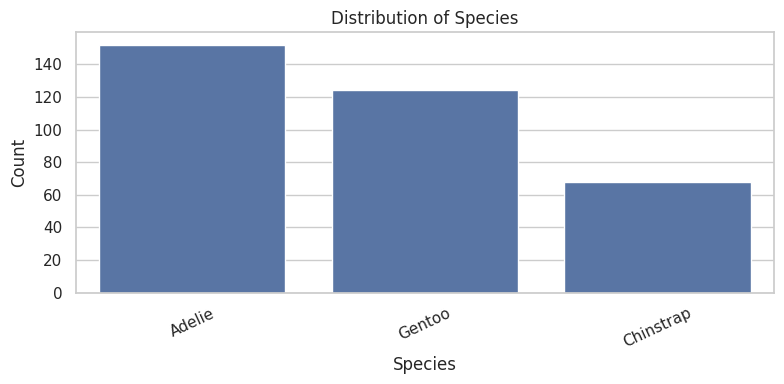

Counts for island:


,count
island,
Biscoe,168
Dream,124
Torgersen,52


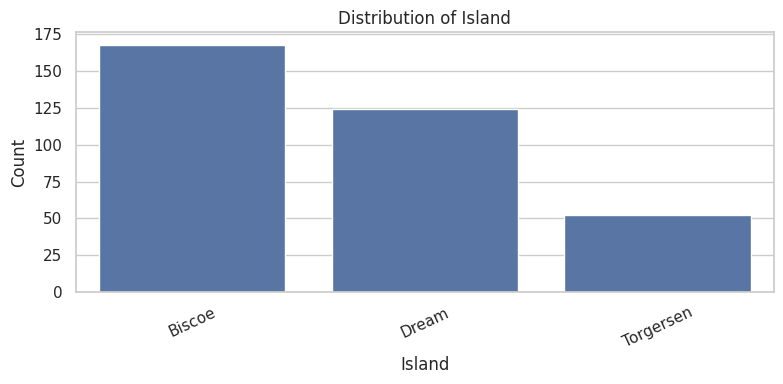

Counts for sex:


,count
sex,
Male,168
Female,165
NaN,11


In [ ]:
for col in ["species", "island", "sex"]:
    if col in eda.columns:
        counts = eda[col].value_counts(dropna=False)
        print(f"Counts for {col}:")
        display(counts.to_frame("count"))

        plt.figure(figsize=(8, 4))
        sns.countplot(data=eda, x=col, order=eda[col].value_counts().index)
        plt.title(f"Distribution of {col.title()}")
        plt.xlabel(col.title())
        plt.ylabel("Count")
        plt.xticks(rotation=25)
        plt.tight_layout()
        plt.show()


## 6. Distribution of numerical features

In [ ]:
numeric_cols = eda.select_dtypes(include=np.number).columns.tolist()
print("Numerical columns:", numeric_cols)

for col in numeric_cols:
    plt.figure(figsize=(8, 4))
    sns.histplot(data=eda, x=col, kde=True)
    plt.title(f"Distribution of {col.replace('_', ' ').title()}")
    plt.xlabel(col.replace("_", " ").title())
    plt.ylabel("Frequency")
    plt.tight_layout()
    plt.show()


## 7. Detect potential outliers with boxplots

In [ ]:
for col in numeric_cols:
    plt.figure(figsize=(8, 3.5))
    sns.boxplot(data=eda, x=col)
    plt.title(f"Boxplot of {col.replace('_', ' ').title()}")
    plt.xlabel(col.replace("_", " ").title())
    plt.tight_layout()
    plt.show()

print("Note: boxplots flag potential outliers; investigate them before deciding whether to remove them.")


## 8. Relationship between numerical features

In [ ]:
# Correlation matrix for numeric columns
corr = eda[numeric_cols].corr(numeric_only=True)
display(corr.round(2))

plt.figure(figsize=(9, 6))
sns.heatmap(corr, annot=True, cmap="coolwarm", fmt=".2f", square=True)
plt.title("Correlation Matrix of Numerical Features")
plt.tight_layout()
plt.show()


## 9. Compare features across penguin species

In [ ]:
if {"species", "body_mass_g"}.issubset(eda.columns):
    plt.figure(figsize=(8, 5))
    sns.boxplot(data=eda, x="species", y="body_mass_g")
    plt.title("Body Mass by Penguin Species")
    plt.xlabel("Species")
    plt.ylabel("Body mass (g)")
    plt.tight_layout()
    plt.show()

if {"species", "flipper_length_mm"}.issubset(eda.columns):
    plt.figure(figsize=(8, 5))
    sns.scatterplot(
        data=eda, x="flipper_length_mm", y="body_mass_g",
        hue="species", style="sex"
    )
    plt.title("Flipper Length vs Body Mass")
    plt.xlabel("Flipper length (mm)")
    plt.ylabel("Body mass (g)")
    plt.tight_layout()
    plt.show()


## 10. Pairwise relationships

In [ ]:
# Pairplot is useful for comparing multiple numerical features.
pair_cols = [c for c in ["bill_length_mm", "bill_depth_mm", "flipper_length_mm", "body_mass_g", "species"] if c in eda.columns]
pair_data = eda[pair_cols].dropna()

if len(pair_data) > 0:
    sns.pairplot(pair_data, hue="species", diag_kind="hist")
    plt.suptitle("Pairwise Relationships by Species", y=1.02)
    plt.show()


## 11. Grouped summary statistics

In [ ]:
group_cols = [c for c in ["species", "island", "sex"] if c in eda.columns]
if group_cols:
    grouped = eda.groupby(group_cols, observed=False)[numeric_cols].agg(["mean", "median", "std", "count"])
    display(grouped.round(2))


## 12. Automated findings summary

In [ ]:
print("=" * 60)
print("EXPLORATORY DATA ANALYSIS — SUMMARY")
print("=" * 60)
print(f"Rows in source dataset: {len(df)}")
print(f"Rows after removing exact duplicates: {len(eda)}")
print(f"Columns: {eda.shape[1]}")
print(f"Rows containing missing values: {eda.isna().any(axis=1).sum()}")

if "species" in eda.columns:
    print("\nSpecies counts:")
    print(eda["species"].value_counts(dropna=False).to_string())

if "island" in eda.columns:
    print("\nIsland counts:")
    print(eda["island"].value_counts(dropna=False).to_string())

if {"flipper_length_mm", "body_mass_g"}.issubset(eda.columns):
    valid = eda[["flipper_length_mm", "body_mass_g"]].dropna()
    if len(valid) > 1:
        corr_value = valid["flipper_length_mm"].corr(valid["body_mass_g"])
        print(f"\nCorrelation between flipper length and body mass: {corr_value:.2f}")

print("\nNumerical summary:")
display(eda[numeric_cols].describe().round(2))
print("=" * 60)


## 13. Export cleaned data (optional)

In [ ]:
cleaned_path = "penguins_eda_cleaned.csv"
eda.to_csv(cleaned_path, index=False)
print("Saved:", cleaned_path)

# In Google Colab, uncomment these lines to download the CSV:
# from google.colab import files
# files.download(cleaned_path)


## 14. Conclusion

This project demonstrates a standard EDA workflow: loading and understanding data, checking missing values and duplicates, analyzing individual variables, inspecting potential outliers, studying correlations, comparing groups, and communicating patterns with visualizations.

Interpret correlations as associations, not proof of causation. Do not remove outliers automatically; use subject-matter reasoning and document any cleaning decisions.

## References
- Palmer Penguins project: https://allisonhorst.github.io/palmerpenguins/
- Pandas documentation: https://pandas.pydata.org/docs/
- Matplotlib documentation: https://matplotlib.org/stable/
- Seaborn documentation: https://seaborn.pydata.org/
